## <span style="color:red"> Import libraries </span>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

## <span style="color:red"> Load prepared dataset </span>

In [2]:
DATA_PATH = Path("../data/processed/sales_prepared.parquet")

sales = pd.read_parquet(DATA_PATH)

print("Prepared dataset loaded successfully.")
print("Shape:", sales.shape)

Prepared dataset loaded successfully.
Shape: (7431525, 35)


In [3]:
sales.head()

,date,item_id,quantity,price_base,sum_total,store_id,dept_name,class_name,subclass_name,item_type,weight_volume,weight_netto,fatness,division,format,city,area,day_of_week,day_of_month,week_of_year,month,quarter,year,is_weekend,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_14,rolling_mean_28,month_sin,month_cos,dow_sin,dow_cos
0,2022-11-11,00179dda14f8,1.00,669.90,669.90,1,ТОВАРЫ ДЛЯ УБОРКИ,"ШВАБРЫ,СОВКИ,ЩЁТКИ",ШВАБРЫ,Швабры,NaN,0.50,NaN,Div1,Format-1,City1,1500,4,11,45,11,4,2022,0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,-0.50,0.87,-0.43,-0.90
1,2022-11-13,00179dda14f8,1.00,669.90,669.90,1,ТОВАРЫ ДЛЯ УБОРКИ,"ШВАБРЫ,СОВКИ,ЩЁТКИ",ШВАБРЫ,Швабры,NaN,0.50,NaN,Div1,Format-1,City1,1500,6,13,45,11,4,2022,1,0.00,0.00,0.00,0.00,0.14,0.07,0.04,-0.50,0.87,-0.78,0.62
2,2022-11-15,00179dda14f8,1.00,669.90,669.90,1,ТОВАРЫ ДЛЯ УБОРКИ,"ШВАБРЫ,СОВКИ,ЩЁТКИ",ШВАБРЫ,Швабры,NaN,0.50,NaN,Div1,Format-1,City1,1500,1,15,46,11,4,2022,0,0.00,0.00,0.00,0.00,0.29,0.14,0.07,-0.50,0.87,0.78,0.62
3,2022-11-22,00179dda14f8,1.00,669.90,669.90,1,ТОВАРЫ ДЛЯ УБОРКИ,"ШВАБРЫ,СОВКИ,ЩЁТКИ",ШВАБРЫ,Швабры,NaN,0.50,NaN,Div1,Format-1,City1,1500,1,22,47,11,4,2022,0,0.00,1.00,0.00,0.00,0.00,0.21,0.11,-0.50,0.87,0.78,0.62
4,2022-12-02,00179dda14f8,1.00,669.90,669.90,1,ТОВАРЫ ДЛЯ УБОРКИ,"ШВАБРЫ,СОВКИ,ЩЁТКИ",ШВАБРЫ,Швабры,NaN,0.50,NaN,Div1,Format-1,City1,1500,4,2,48,12,4,2022,0,0.00,0.00,0.00,0.00,0.00,0.07,0.14,-0.00,1.00,-0.43,-0.90


In [3]:
# Confirm the date range
print("Start date:", sales["date"].min().date())
print("End date:", sales["date"].max().date())

print(
    "Total calendar days:",
    (sales["date"].max() - sales["date"].min()).days + 1
)

Start date: 2022-08-28
End date: 2024-09-26
Total calendar days: 761


## <span style="color:red"> Target variable summary </span>

<span style="color:green"> __The target is "quantity"__ </span>

In [4]:
sales["quantity"].describe()

count   7431525.00
mean          5.64
std          27.40
min           0.00
25%           1.00
50%           2.00
75%           4.68
max        4952.00
Name: quantity, dtype: float64

In [5]:
print("Total demand:", sales["quantity"].sum())
print("Average demand per record:", sales["quantity"].mean())
print("Median demand:", sales["quantity"].median())
print("Maximum demand:", sales["quantity"].max())

Total demand: 41949558.044
Average demand per record: 5.644811535182886
Median demand: 2.0
Maximum demand: 4952.0


In [6]:
# Check zero-demand records
zero_quantity = (sales["quantity"] == 0).sum()

print("Zero-quantity records:", zero_quantity)
print(
    "Percentage of records with zero quantity:",
    round(zero_quantity / len(sales) * 100, 2),
    "%"
)

Zero-quantity records: 2438
Percentage of records with zero quantity: 0.03 %


# <span style="color:red"> EDA Stage 2 — Branch-wise Demand Analysis </span>

In [7]:
# Store summary
store_summary = (
    sales.groupby("store_id")
    .agg(
        records=("quantity", "size"),
        total_demand=("quantity", "sum"),
        average_demand=("quantity", "mean"),
        median_demand=("quantity", "median"),
        max_demand=("quantity", "max")
    )
    .reset_index()
)

store_summary

,store_id,records,total_demand,average_demand,median_demand,max_demand
0,1,3682934,23074491.38,6.27,2.00,4656.00
1,2,1337790,4898962.56,3.66,2.00,818.00
2,3,830455,4755665.46,5.73,2.00,774.00
3,4,1580346,9220438.65,5.83,2.00,4952.00


In [8]:
# Demand share by store
store_summary["demand_share_pct"] = (
    store_summary["total_demand"]
    / store_summary["total_demand"].sum()
    * 100
)

store_summary

,store_id,records,total_demand,average_demand,median_demand,max_demand,demand_share_pct
0,1,3682934,23074491.38,6.27,2.00,4656.00,55.01
1,2,1337790,4898962.56,3.66,2.00,818.00,11.68
2,3,830455,4755665.46,5.73,2.00,774.00,11.34
3,4,1580346,9220438.65,5.83,2.00,4952.00,21.98


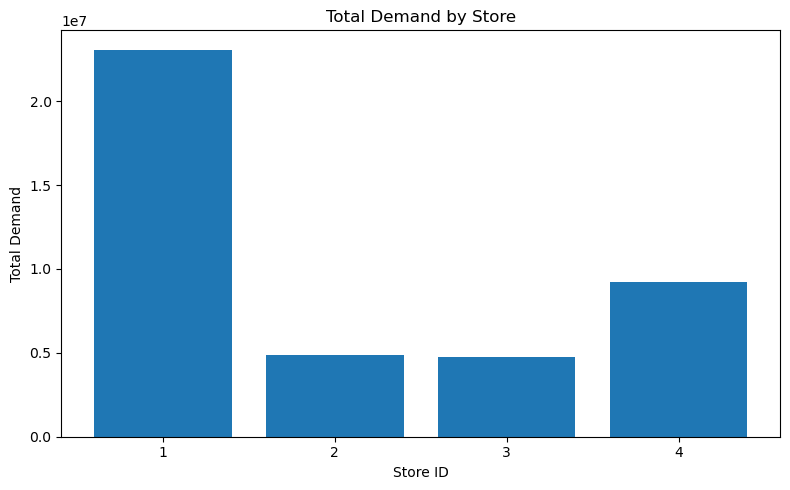

In [9]:
# Visualize total demand by branch
plt.figure(figsize=(8, 5))

plt.bar(
    store_summary["store_id"].astype(str),
    store_summary["total_demand"]
)

plt.xlabel("Store ID")
plt.ylabel("Total Demand")
plt.title("Total Demand by Store")
plt.tight_layout()
plt.show()

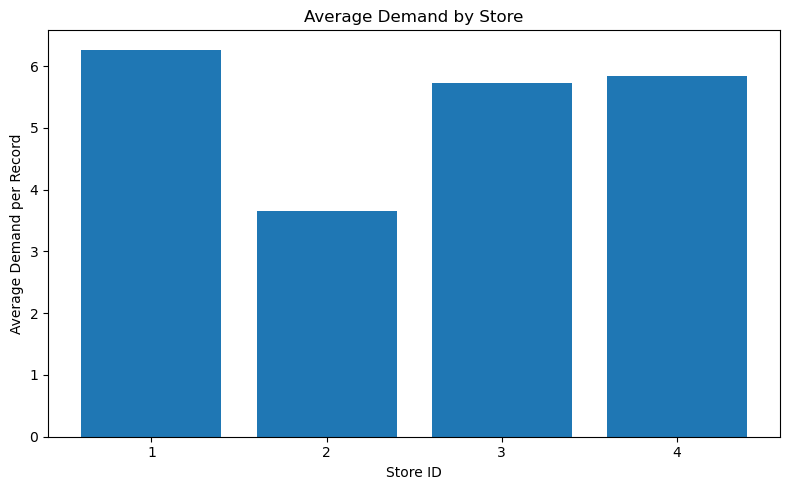

In [11]:
# Average demand by branch
plt.figure(figsize=(8, 5))

plt.bar(
    store_summary["store_id"].astype(str),
    store_summary["average_demand"]
)

plt.xlabel("Store ID")
plt.ylabel("Average Demand per Record")
plt.title("Average Demand by Store")
plt.tight_layout()
plt.show()

# <span style="color:red"> EDA Stage 3 — Overall Demand Trend </span>

In [12]:
# Daily total demand
daily_demand = (
    sales.groupby("date")["quantity"]
    .sum()
    .reset_index()
)

daily_demand.head()

,date,quantity
0,2022-08-28,35617.58
1,2022-08-29,41937.09
2,2022-08-30,41002.84
3,2022-08-31,43390.21
4,2022-09-01,50627.40


In [13]:
# Daily demand statistics
daily_demand["quantity"].describe()

count      761.00
mean     55124.25
std      19326.16
min      19345.76
25%      40073.86
50%      44753.82
75%      71721.08
max     154068.88
Name: quantity, dtype: float64

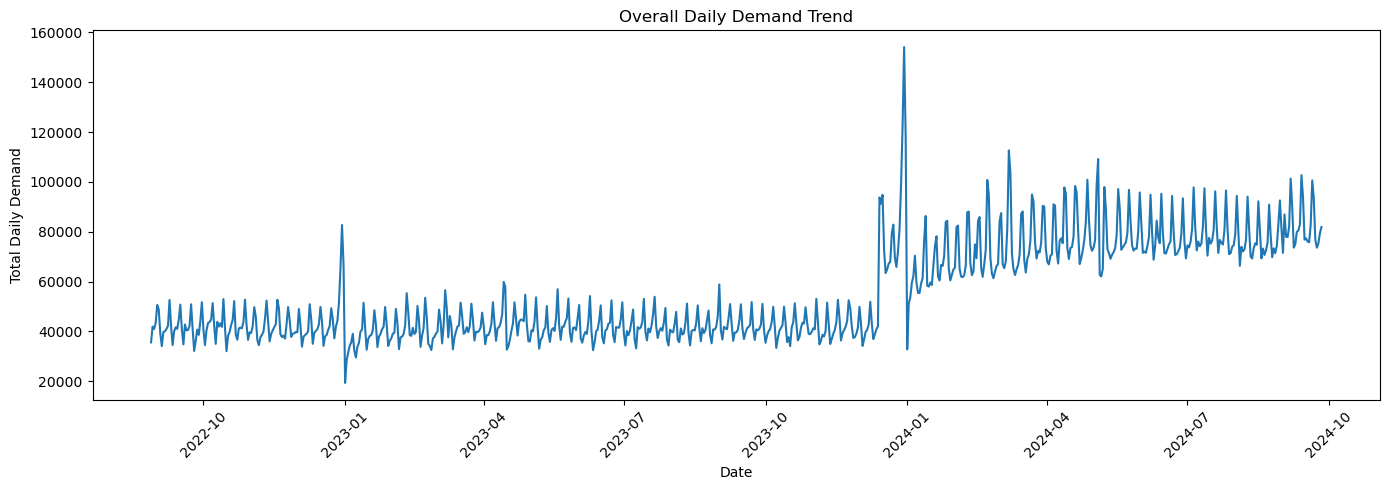

In [14]:
# Plot overall daily demand
plt.figure(figsize=(14, 5))

plt.plot(
    daily_demand["date"],
    daily_demand["quantity"]
)

plt.xlabel("Date")
plt.ylabel("Total Daily Demand")
plt.title("Overall Daily Demand Trend")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
# Monthly demand
# For a clearer long-term trend, aggregate by month.

monthly_demand = (
    sales.assign(
        month_period=sales["date"].dt.to_period("M")
    )
    .groupby("month_period")["quantity"]
    .sum()
    .reset_index()
)

monthly_demand["month"] = (
    monthly_demand["month_period"].dt.to_timestamp()
)

monthly_demand.head()

,month_period,quantity,month
0,2022-08,161947.72,2022-08-01
1,2022-09,1260658.33,2022-09-01
2,2022-10,1306593.73,2022-10-01
3,2022-11,1253998.82,2022-11-01
4,2022-12,1386155.20,2022-12-01


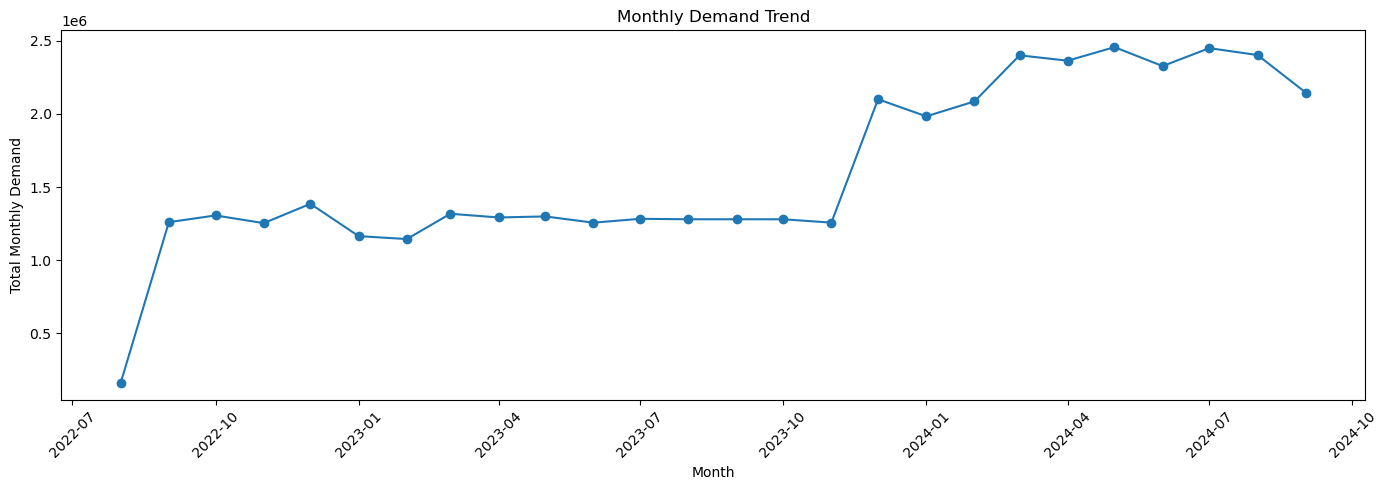

In [16]:
# Plot monthly demand
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_demand["month"],
    monthly_demand["quantity"],
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Total Monthly Demand")
plt.title("Monthly Demand Trend")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# <span style="color:red"> EDA Stage 4 — Weekly Seasonality </span>

In [17]:
# Demand by day of week
weekly_demand = (
    sales.groupby("day_of_week")["quantity"]
    .agg(["sum", "mean", "median", "count"])
    .reset_index()
)

weekly_demand

,day_of_week,sum,mean,median,count
0,0,5451646.35,5.39,2.00,1011148
1,1,5606056.06,5.42,2.00,1034405
2,2,5795753.97,5.51,2.00,1051281
3,3,6196976.28,5.72,2.00,1082673
4,4,7207576.63,6.23,2.00,1156014
5,5,6387796.61,5.86,2.00,1090764
6,6,5303752.15,5.28,2.00,1005240


In [18]:
# Add day names
day_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

weekly_demand["day_name"] = (
    weekly_demand["day_of_week"].map(day_names)
)

weekly_demand

,day_of_week,sum,mean,median,count,day_name
0,0,5451646.35,5.39,2.00,1011148,Monday
1,1,5606056.06,5.42,2.00,1034405,Tuesday
2,2,5795753.97,5.51,2.00,1051281,Wednesday
3,3,6196976.28,5.72,2.00,1082673,Thursday
4,4,7207576.63,6.23,2.00,1156014,Friday
5,5,6387796.61,5.86,2.00,1090764,Saturday
6,6,5303752.15,5.28,2.00,1005240,Sunday


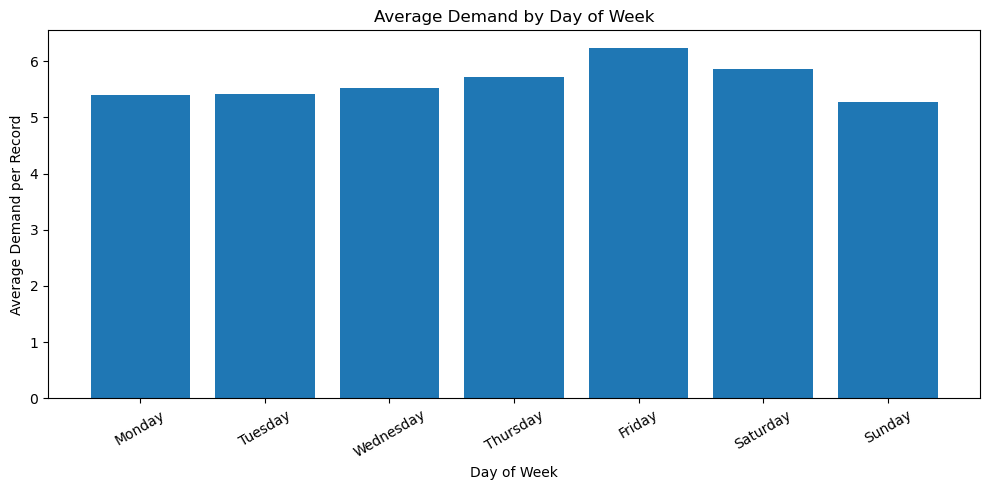

In [19]:
# Plot average demand by weekday
plt.figure(figsize=(10, 5))

plt.bar(
    weekly_demand["day_name"],
    weekly_demand["mean"]
)

plt.xlabel("Day of Week")
plt.ylabel("Average Demand per Record")
plt.title("Average Demand by Day of Week")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [20]:
# Weekend vs weekday
weekend_demand = (
    sales.groupby("is_weekend")["quantity"]
    .agg(["mean", "median", "sum", "count"])
    .reset_index()
)

weekend_demand["day_type"] = weekend_demand["is_weekend"].map({
    0: "Weekday",
    1: "Weekend"
})

weekend_demand

,is_weekend,mean,median,sum,count,day_type
0,0,5.67,2.00,30258009.29,5335521,Weekday
1,1,5.58,2.00,11691548.76,2096004,Weekend


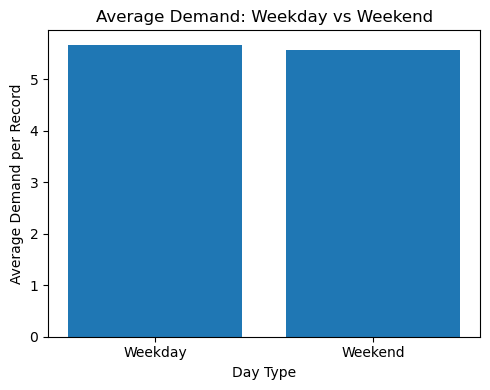

In [22]:
# Compare weekday and weekend
plt.figure(figsize=(5, 4))

plt.bar(
    weekend_demand["day_type"],
    weekend_demand["mean"]
)

plt.xlabel("Day Type")
plt.ylabel("Average Demand per Record")
plt.title("Average Demand: Weekday vs Weekend")
plt.tight_layout()
plt.show()

# <span style="color:red"> EDA Stage 5 — Monthly Seasonality </span>

In [23]:
# Demand by month
monthly_seasonality = (
    sales.groupby("month")["quantity"]
    .agg(["sum", "mean", "median", "count"])
    .reset_index()
)

monthly_seasonality

,month,sum,mean,median,count
0,1,3149219.54,5.27,2.00,597637
1,2,3231096.80,5.48,2.00,589420
2,3,3718983.02,5.65,2.00,657763
3,4,3656998.68,5.66,2.00,646211
4,5,3756809.66,5.69,2.00,659933
5,6,3584719.54,5.63,2.00,637109
6,7,3733520.29,5.67,2.00,658366
7,8,3845407.83,5.59,2.00,688209
8,9,4687481.36,5.88,2.00,796578
9,10,2586871.69,5.61,2.00,461245


In [24]:
# Month names
month_names = {
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October",
    11: "November",
    12: "December"
}

monthly_seasonality["month_name"] = (
    monthly_seasonality["month"].map(month_names)
)

monthly_seasonality

,month,sum,mean,median,count,month_name
0,1,3149219.54,5.27,2.00,597637,January
1,2,3231096.80,5.48,2.00,589420,February
2,3,3718983.02,5.65,2.00,657763,March
3,4,3656998.68,5.66,2.00,646211,April
4,5,3756809.66,5.69,2.00,659933,May
5,6,3584719.54,5.63,2.00,637109,June
6,7,3733520.29,5.67,2.00,658366,July
7,8,3845407.83,5.59,2.00,688209,August
8,9,4687481.36,5.88,2.00,796578,September
9,10,2586871.69,5.61,2.00,461245,October


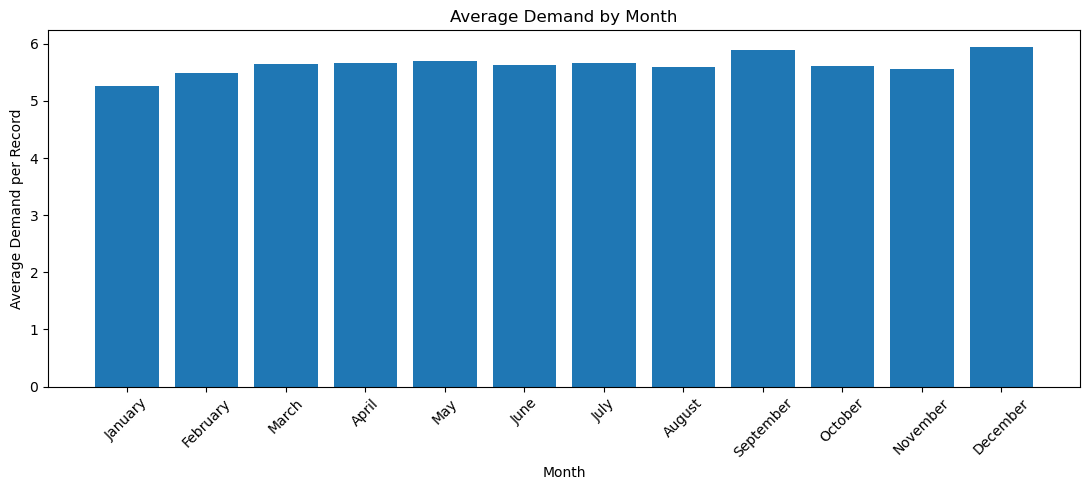

In [26]:
# Plot monthly average demand
plt.figure(figsize=(11, 5))

plt.bar(
    monthly_seasonality["month_name"],
    monthly_seasonality["mean"]
)

plt.xlabel("Month")
plt.ylabel("Average Demand per Record")
plt.title("Average Demand by Month")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# <span style="color:red"> EDA Stage 6 — Year-over-Year Seasonal Pattern </span>

In [27]:
# Create year-month daily demand
daily_year_month = (
    sales.groupby(["year", "month", "date"])["quantity"]
    .sum()
    .reset_index()
)

daily_year_month.head()

,year,month,date,quantity
0,2022,8,2022-08-28,35617.58
1,2022,8,2022-08-29,41937.09
2,2022,8,2022-08-30,41002.84
3,2022,8,2022-08-31,43390.21
4,2022,9,2022-09-01,50627.40


In [28]:
# Average daily demand by year and month
year_month_demand = (
    daily_year_month
    .groupby(["year", "month"])["quantity"]
    .mean()
    .reset_index()
)

year_month_demand

,year,month,quantity
0,2022,8,40486.93
1,2022,9,42021.94
2,2022,10,42148.18
3,2022,11,41799.96
4,2022,12,44714.68
5,2023,1,37590.87
6,2023,2,40898.90
7,2023,3,42519.20
8,2023,4,43091.83
9,2023,5,41930.44


In [29]:
# Pivot for easy comparison
year_month_pivot = year_month_demand.pivot(
    index="month",
    columns="year",
    values="quantity"
)

year_month_pivot

year,2022,2023,2024
month,,,
1,NaN,37590.87,63996.85
2,NaN,40898.90,71928.54
3,NaN,42519.20,77447.99
4,NaN,43091.83,78808.13
5,NaN,41930.44,79256.97
6,NaN,41907.89,77582.76
7,NaN,41404.79,79031.35
8,40486.93,41306.43,77514.87
9,42021.94,42684.38,82549.68


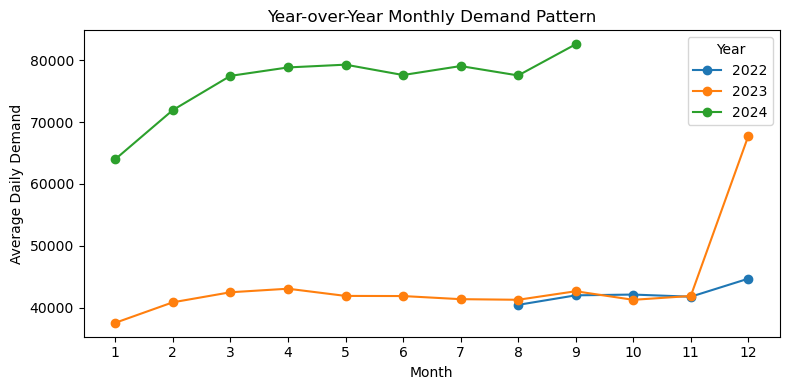

In [31]:
# Plot year-over-year monthly demand
plt.figure(figsize=(8, 4))

for year in year_month_demand["year"].unique():
    data = year_month_demand[
        year_month_demand["year"] == year
    ]
    
    plt.plot(
        data["month"],
        data["quantity"],
        marker="o",
        label=str(year)
    )

plt.xlabel("Month")
plt.ylabel("Average Daily Demand")
plt.title("Year-over-Year Monthly Demand Pattern")
plt.xticks(range(1, 13))
plt.legend(title="Year")
plt.tight_layout()
plt.show()

# <span style="color:red"> EDA Stage 7 — Product-Level Demand </span>

In [32]:
# Product activity summary
product_summary = (
    sales.groupby("item_id")
    .agg(
        stores=("store_id", "nunique"),
        records=("quantity", "size"),
        total_demand=("quantity", "sum"),
        average_demand=("quantity", "mean"),
        median_demand=("quantity", "median"),
        max_demand=("quantity", "max")
    )
    .reset_index()
)

product_summary.head()

,item_id,stores,records,total_demand,average_demand,median_demand,max_demand
0,00179dda14f8,1,22,22.00,1.00,1.00,1.00
1,001829cb707d,4,1353,3585.00,2.65,2.00,18.00
2,001a4fbee4ce,2,5,5.00,1.00,1.00,1.00
3,001b302a9387,4,905,3158.00,3.49,3.00,25.00
4,001dadca6678,3,814,536.63,0.66,0.47,5.09


In [33]:
# Overall product statistics
product_summary[
    [
        "stores",
        "records",
        "total_demand",
        "average_demand",
        "median_demand",
        "max_demand"
    ]
].describe()

,stores,records,total_demand,average_demand,median_demand,max_demand
count,28182.00,28182.00,28182.00,28182.00,28182.00,28182.00
mean,2.06,263.70,1488.52,2.81,2.11,15.42
std,0.99,408.03,14534.81,12.66,8.70,66.67
min,1.00,1.00,0.00,0.00,0.00,0.00
25%,1.00,16.00,21.00,1.15,1.00,2.00
50%,2.00,80.00,122.88,1.50,1.00,5.00
75%,3.00,332.75,699.00,2.38,2.00,13.00
max,4.00,2571.00,2023140.00,1526.87,1029.50,4952.00


In [34]:
# Top 10 products by total demand
top_products = (
    product_summary
    .sort_values("total_demand", ascending=False)
    .head(10)
)

top_products

,item_id,stores,records,total_demand,average_demand,median_demand,max_demand
19572,b0d24502fb66,4,2275,2023140.00,889.29,345.00,4656.00
17155,9a7e315f3f42,4,2007,563403.01,280.72,260.59,1158.15
10988,63161948a95a,1,761,434289.00,570.68,558.00,1219.00
25294,e5b2b6f57ea7,4,2571,358707.00,139.52,114.00,431.00
1050,0973df3ff57f,4,2565,344912.92,134.47,64.13,870.32
20086,b5aac3497e3f,4,1712,230549.00,134.67,134.00,503.00
12088,6d284b4e9982,4,2547,205106.00,80.53,37.00,4243.00
10138,5b8e114fdf6f,4,1352,174563.04,129.11,40.49,1457.24
17248,9b4865c6faf1,4,2072,170768.00,82.42,45.00,808.00
19215,ad5239463b05,4,2406,168752.00,70.14,39.00,278.00


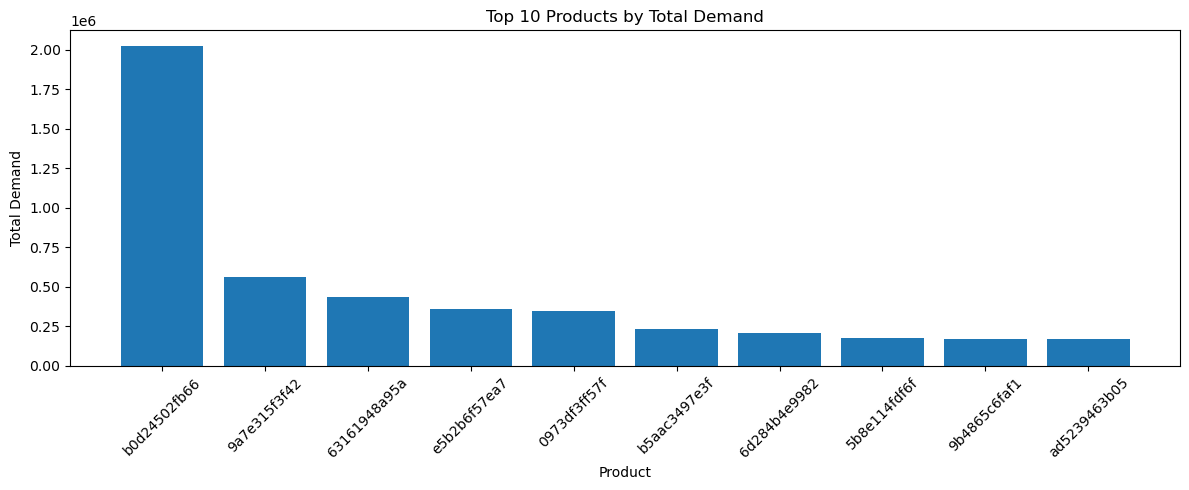

In [35]:
# Plot top 10 products
plt.figure(figsize=(12, 5))

plt.bar(
    top_products["item_id"].astype(str),
    top_products["total_demand"]
)

plt.xlabel("Product")
plt.ylabel("Total Demand")
plt.title("Top 10 Products by Total Demand")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# <span style="color:red"> EDA Stage 8 — Product × Store Demand </span>

In [36]:
# Product-store summary
product_store_summary = (
    sales.groupby(["item_id", "store_id"])
    .agg(
        records=("quantity", "size"),
        total_demand=("quantity", "sum"),
        average_demand=("quantity", "mean"),
        median_demand=("quantity", "median"),
        max_demand=("quantity", "max")
    )
    .reset_index()
)

product_store_summary.head()

,item_id,store_id,records,total_demand,average_demand,median_demand,max_demand
0,00179dda14f8,1,22,22.00,1.00,1.00,1.00
1,001829cb707d,1,626,2048.00,3.27,2.00,18.00
2,001829cb707d,2,473,868.00,1.84,1.00,8.00
3,001829cb707d,3,35,85.00,2.43,2.00,6.00
4,001829cb707d,4,219,584.00,2.67,2.00,12.00


In [37]:
# Summary statistics
product_store_summary[
    [
        "records",
        "total_demand",
        "average_demand",
        "median_demand",
        "max_demand"
    ]
].describe()

,records,total_demand,average_demand,median_demand,max_demand
count,58025.00,58025.00,58025.00,58025.00,58025.00
mean,128.07,722.96,3.19,2.59,12.69
std,165.26,6907.64,21.35,19.62,55.92
min,1.00,0.00,0.00,0.00,0.00
25%,14.00,20.00,1.16,1.00,2.00
50%,57.00,89.00,1.51,1.00,5.00
75%,179.00,393.00,2.48,2.00,11.00
max,761.00,1224632.00,3159.40,2794.00,4952.00


In [38]:
# How many product-store combinations?
print(
    "Total product-store combinations:",
    len(product_store_summary)
)

print(
    "Products:",
    sales["item_id"].nunique()
)

print(
    "Stores:",
    sales["store_id"].nunique()
)

Total product-store combinations: 58025
Products: 28182
Stores: 4


In [39]:
# Products available across stores
products_by_store_count = (
    product_store_summary
    .groupby("item_id")["store_id"]
    .nunique()
    .value_counts()
    .sort_index()
)

products_by_store_count

store_id
1     9777
2    10180
3     5012
4     3213
Name: count, dtype: int64

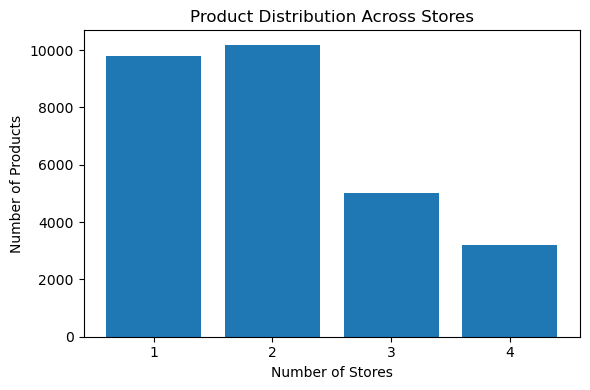

In [44]:
# Plot product distribution across stores
plt.figure(figsize=(6, 4))

plt.bar(
    products_by_store_count.index.astype(str),
    products_by_store_count.values
)

plt.xlabel("Number of Stores")
plt.ylabel("Number of Products")
plt.title("Product Distribution Across Stores")
plt.tight_layout()
plt.show()

# <span style="color:red"> EDA Stage 9 — Category / Department Analysis </span>

In [45]:
# Department summary
department_summary = (
    sales.groupby("dept_name", dropna=False)["quantity"]
    .agg(
        records="size",
        total_demand="sum",
        average_demand="mean",
        median_demand="median"
    )
    .reset_index()
    .sort_values("total_demand", ascending=False)
)

department_summary

,dept_name,records,total_demand,average_demand,median_demand
18,ВСПОМОГАТЕЛЬНАЯ ГРУППА,15259,3111278.00,203.90,14.00
168,ХЛЕБ,137646,2735210.33,19.87,9.00
166,ФРУКТЫ,126064,2079786.53,16.50,4.36
163,ТРАДИЦИОННЫЕ МОЛОЧНЫЕ ПРОДУКТЫ,206174,1611961.92,7.82,5.00
91,ОВОЩИ,107921,1577368.06,14.62,3.60
...,...,...,...,...,...
116,РЫБА СВЕЖАЯ НЕ ИСПОЛЬЗОВАТЬ,40,34.83,0.87,0.39
70,ЛЕПИМ-ВАРИМ,7,17.57,2.51,2.83
4,АКЦИЯ ЛОЯЛЬНОСТИ (НЕ ИСПОЛЬЗОВАТЬ),5,16.00,3.20,4.00
104,ПОДАРОЧНЫЕ КОРЗИНЫ,5,5.00,1.00,1.00


In [47]:
# Top departments by total demand
department_summary.head(10)

,dept_name,records,total_demand,average_demand,median_demand
18,ВСПОМОГАТЕЛЬНАЯ ГРУППА,15259,3111278.00,203.90,14.00
168,ХЛЕБ,137646,2735210.33,19.87,9.00
166,ФРУКТЫ,126064,2079786.53,16.50,4.36
163,ТРАДИЦИОННЫЕ МОЛОЧНЫЕ ПРОДУКТЫ,206174,1611961.92,7.82,5.00
91,ОВОЩИ,107921,1577368.06,14.62,3.60
137,СОВРЕМЕННАЯ МОЛОЧНАЯ КАТЕГОРИЯ,275570,1242398.00,4.51,3.00
100,ПИРОГИ,42342,1204473.29,28.45,19.00
15,ВОДА,115067,1039019.00,9.03,4.00
99,ПИВО,240118,1006966.00,4.19,2.00
102,ПИЦЦА,44684,977259.00,21.87,12.00


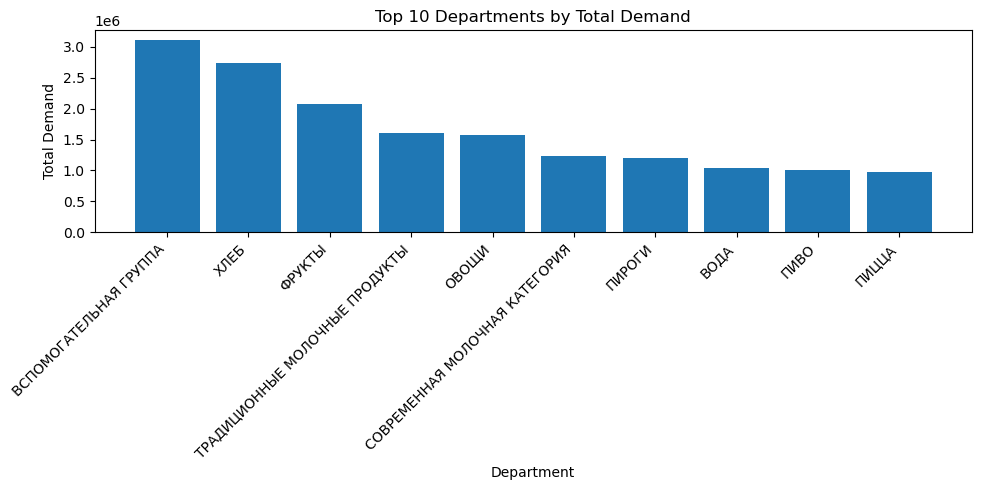

In [52]:
# Plot top 10 departments
top_departments = department_summary.head(10)

plt.figure(figsize=(10, 5))

plt.bar(
    top_departments["dept_name"].astype(str),
    top_departments["total_demand"]
)

plt.xlabel("Department")
plt.ylabel("Total Demand")
plt.title("Top 10 Departments by Total Demand")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [49]:
# Average demand by department
top_avg_departments = (
    department_summary
    .sort_values("average_demand", ascending=False)
    .head(10)
)

top_avg_departments

,dept_name,records,total_demand,average_demand,median_demand
18,ВСПОМОГАТЕЛЬНАЯ ГРУППА,15259,3111278.00,203.90,14.00
30,ДОМАШНЯЯ КУХНЯ,3182,625624.92,196.61,135.48
46,КАФЕ,27238,861457.00,31.63,13.00
100,ПИРОГИ,42342,1204473.29,28.45,19.00
182,ЯЙЦО,16820,402939.00,23.96,8.00
102,ПИЦЦА,44684,977259.00,21.87,12.00
168,ХЛЕБ,137646,2735210.33,19.87,9.00
175,ШАУРМА,11694,224760.00,19.22,14.00
126,СДОБА,29703,563554.28,18.97,11.00
135,СЛОЙКА,44530,794291.17,17.84,11.00


In [51]:
# Check missing department values
# Although we already handled the categorical missing values during preparation, we'll see how many records have unknown department information.

print(
    "Records with missing department:",
    sales["dept_name"].isna().sum()
)

print(
    "Percentage:",
    round(sales["dept_name"].isna().mean() * 100, 2),
    "%"
)

Records with missing department: 0
Percentage: 0.0 %


# <span style="color:red"> EDA Stage 10 — Outlier Analysis </span>

In [53]:
# Demand percentiles
sales["quantity"].quantile(
    [0.90, 0.95, 0.99, 0.995, 0.999]
)

0.90    10.00
0.95    18.00
0.99    57.00
0.99    86.00
1.00   241.01
Name: quantity, dtype: float64

In [54]:
# IQR-based outlier threshold
Q1 = sales["quantity"].quantile(0.25)
Q3 = sales["quantity"].quantile(0.75)

IQR = Q3 - Q1

upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper outlier threshold:", upper_limit)

Q1: 1.0
Q3: 4.68
IQR: 3.6799999999999997
Upper outlier threshold: 10.2


In [55]:
# Count high-demand records
outlier_count = (
    sales["quantity"] > upper_limit
).sum()

print("Potential high-demand records:", outlier_count)

print(
    "Percentage:",
    round(outlier_count / len(sales) * 100, 2),
    "%"
)

Potential high-demand records: 733842
Percentage: 9.87 %


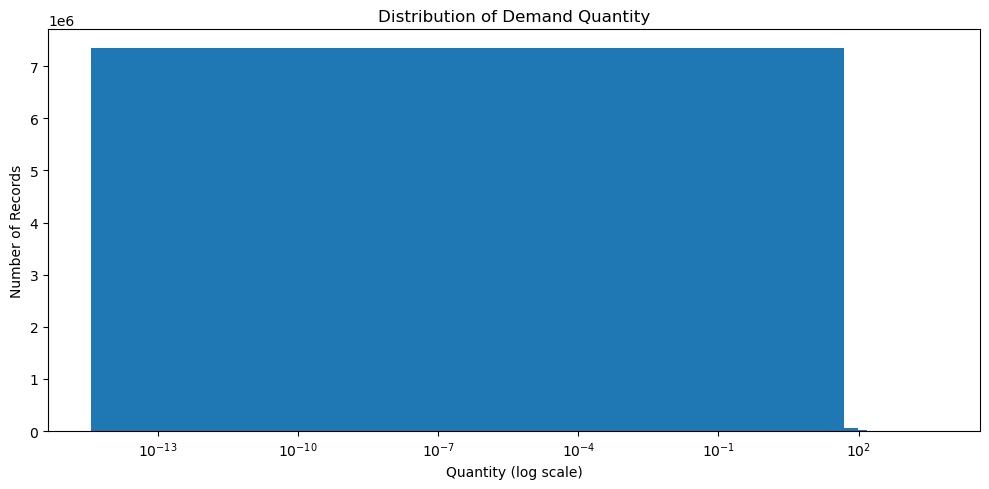

In [56]:
# Visualize demand distribution
plt.figure(figsize=(10, 5))

plt.hist(
    sales["quantity"],
    bins=100
)

plt.xscale("log")

plt.xlabel("Quantity (log scale)")
plt.ylabel("Number of Records")
plt.title("Distribution of Demand Quantity")
plt.tight_layout()
plt.show()

# <span style="color:red"> EDA Stage 11 — Check sum_total for Target Leakage </span>

In [57]:
# Check relationship between quantity, price and sum_total
sales[["quantity", "price_base", "sum_total"]].corr()

,quantity,price_base,sum_total
quantity,1.00,-0.04,0.41
price_base,-0.04,1.00,0.11
sum_total,0.41,0.11,1.00


In [58]:
# Check whether sum_total ≈ quantity × price_base
sales["calculated_total"] = (
    sales["quantity"] * sales["price_base"]
)

difference = (
    sales["sum_total"] - sales["calculated_total"]
).abs()

print("Mean absolute difference:", difference.mean())
print("Median absolute difference:", difference.median())
print("Maximum absolute difference:", difference.max())

Mean absolute difference: 0.02105433035615771
Median absolute difference: 0.0
Maximum absolute difference: 2788.0


In [59]:
# Percentage of records where they match
match_pct = (
    difference < 0.01
).mean() * 100

print(
    "Percentage approximately matching quantity × price:",
    round(match_pct, 2),
    "%"
)

Percentage approximately matching quantity × price: 85.99 %


In [60]:
# One cleanup cell afterward
# Since calculated_total is only for this investigation:
sales.drop(columns=["calculated_total"], inplace=True)

In [61]:
# Average demand by store and month
store_month_demand = (
    sales.groupby(["store_id", "month"])["quantity"]
    .mean()
    .reset_index()
)

store_month_demand.head()

,store_id,month,quantity
0,1,1,6.03
1,1,2,6.22
2,1,3,6.32
3,1,4,6.27
4,1,5,6.31


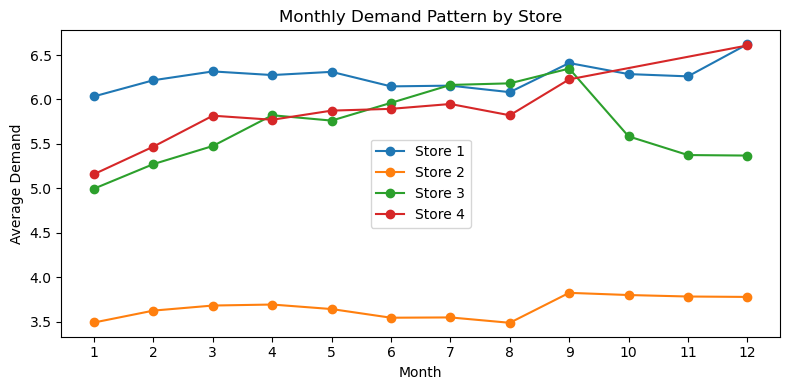

In [63]:
# Plot branch-wise monthly pattern
plt.figure(figsize=(8, 4))

for store in store_month_demand["store_id"].unique():
    data = store_month_demand[
        store_month_demand["store_id"] == store
    ]
    
    plt.plot(
        data["month"],
        data["quantity"],
        marker="o",
        label=f"Store {store}"
    )

plt.xlabel("Month")
plt.ylabel("Average Demand")
plt.title("Monthly Demand Pattern by Store")
plt.xticks(range(1, 13))
plt.legend()
plt.tight_layout()
plt.show()

# <span style="color:red"> EDA Stage 12 — Price and Demand Relationship </span>

In [64]:
# Price statistics
price_stats = sales["price_base"].describe()
price_stats

count   7431525.00
mean        207.53
std         336.90
min      -10390.00
25%          60.00
50%         109.90
75%         199.90
max       28999.90
Name: price_base, dtype: float64

In [65]:
# Check missing and zero prices
print("Missing prices:", sales["price_base"].isna().sum())
print("Zero prices:", (sales["price_base"] == 0).sum())
print("Negative prices:", (sales["price_base"] < 0).sum())

Missing prices: 0
Zero prices: 8018
Negative prices: 26


In [66]:
# Price vs quantity correlation
price_quantity_corr = sales[
    ["price_base", "quantity"]
].corr()

price_quantity_corr

,price_base,quantity
price_base,1.00,-0.04
quantity,-0.04,1.00


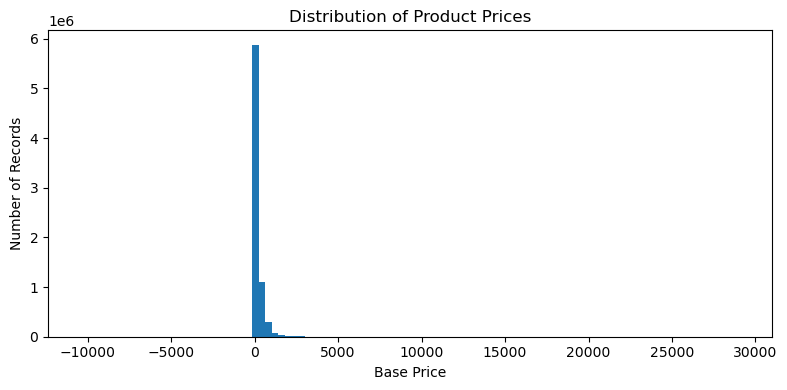

In [69]:
# Price distribution
plt.figure(figsize=(8,4))

plt.hist(
    sales["price_base"].dropna(),
    bins=100
)

plt.xlabel("Base Price")
plt.ylabel("Number of Records")
plt.title("Distribution of Product Prices")
plt.tight_layout()
plt.show()

In [70]:
# Average demand by price range
# Instead of looking at millions of individual points, divide prices into quantile-based groups.

price_analysis = sales[
    ["price_base", "quantity"]
].dropna().copy()

price_analysis["price_group"] = pd.qcut(
    price_analysis["price_base"],
    q=5,
    duplicates="drop"
)

price_group_summary = (
    price_analysis
    .groupby("price_group", observed=True)["quantity"]
    .agg(
        records="size",
        average_demand="mean",
        median_demand="median"
    )
    .reset_index()
)

price_group_summary

,price_group,records,average_demand,median_demand
0,"(-10390.001, 54.9]",1518714,10.74,4.00
1,"(54.9, 89.57]",1453989,5.23,2.00
2,"(89.57, 139.9]",1568944,4.67,2.00
3,"(139.9, 255.18]",1403581,3.72,2.00
4,"(255.18, 28999.9]",1486297,3.69,1.00


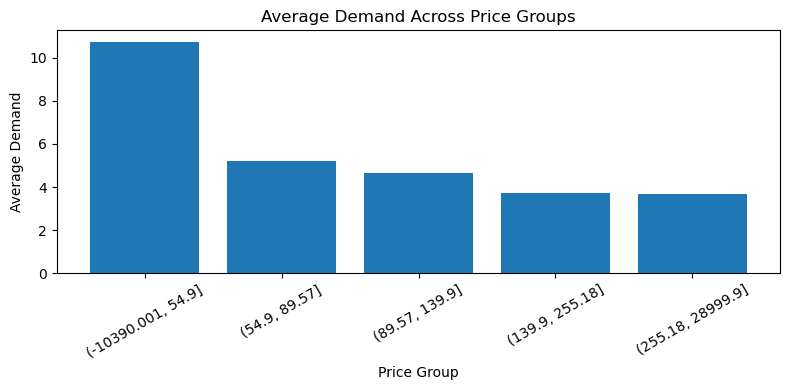

In [72]:
# Plot demand across price groups
plt.figure(figsize=(8, 4))

plt.bar(
    price_group_summary["price_group"].astype(str),
    price_group_summary["average_demand"]
)

plt.xlabel("Price Group")
plt.ylabel("Average Demand")
plt.title("Average Demand Across Price Groups")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# <span style="color:red"> EDA Stage 13 — Investigate abnormal prices </span>

In [73]:
# Inspect negative prices
negative_price_records = sales[
    sales["price_base"] < 0
][[
    "date",
    "item_id",
    "store_id",
    "quantity",
    "price_base",
    "sum_total"
]]

negative_price_records

,date,item_id,store_id,quantity,price_base,sum_total
134710,2022-09-08,09af0fa691eb,1,0.04,-1867.27,-82.16
409111,2023-01-14,1b3367edc2a7,1,1.00,-117.71,-117.71
548098,2023-05-28,253ab68ae78c,1,1.00,-590.10,-590.10
589313,2024-06-23,2833d55d84a7,1,1.00,-30.10,-30.10
606049,2022-12-09,294c9882366e,1,0.07,-759.00,-53.13
707315,2024-04-05,303f02044ca2,1,2.00,-50.05,-100.10
852896,2022-11-16,3a3a00061e41,1,1.00,-61.10,-61.10
945408,2024-07-28,414adcb091ba,1,1.00,-140.10,-140.10
1022401,2024-05-18,45ec31162fbd,1,1.00,-551.00,-551.00
1098171,2023-12-22,4b797bb271c0,1,1.00,-20.20,-20.20


In [74]:
# Inspect zero-price records
zero_price_summary = sales[
    sales["price_base"] == 0
][[
    "quantity",
    "sum_total"
]].describe()

zero_price_summary

,quantity,sum_total
count,8018.00,8018.00
mean,0.99,-8.00
std,4.23,85.52
min,0.00,-2788.00
25%,0.00,0.00
50%,1.00,0.00
75%,1.00,0.00
max,360.00,1399.00


In [77]:
# Check whether zero price has actual sales value
zero_price_records = sales[sales["price_base"] == 0]

print("Zero-price records:", len(zero_price_records))
print(
    "Zero-price records with positive quantity:",
    (zero_price_records["quantity"] > 0).sum()
)
print(
    "Zero-price records with positive sales value:",
    (zero_price_records["sum_total"] > 0).sum()
)

Zero-price records: 8018
Zero-price records with positive quantity: 5580
Zero-price records with positive sales value: 960


In [79]:
# Check negative-price records' sales value
print(
    "Negative-price records:",
    len(negative_price_records)
)

print(
    "Negative-price records with positive quantity:",
    (negative_price_records["quantity"] > 0).sum()
)

print(
    "Negative-price records with positive sales value:",
    (negative_price_records["sum_total"] > 0).sum())

Negative-price records: 26
Negative-price records with positive quantity: 26
Negative-price records with positive sales value: 0


In [80]:
# Fix negative prices
sales.loc[sales["price_base"] < 0, "price_base"] = np.nan

print(
    "Negative prices remaining:",
    (sales["price_base"] < 0).sum()
)

print(
    "Missing prices after correction:",
    sales["price_base"].isna().sum()
)

Negative prices remaining: 0
Missing prices after correction: 26


# <span style="color:red">EDA Stage 14 — Demand Variability </span>

In [82]:
# Product-store demand variability
item_store_variability = (
    sales.groupby(["item_id", "store_id"])["quantity"]
    .agg(
        records="count",
        average_demand="mean",
        std_demand="std",
        min_demand="min",
        max_demand="max"
    )
    .reset_index()
)

item_store_variability["cv"] = (
    item_store_variability["std_demand"]
    / item_store_variability["average_demand"]
)

item_store_variability.head()

,item_id,store_id,records,average_demand,std_demand,min_demand,max_demand,cv
0,00179dda14f8,1,22,1.00,0.00,1.00,1.00,0.00
1,001829cb707d,1,626,3.27,2.65,1.00,18.00,0.81
2,001829cb707d,2,473,1.84,1.15,1.00,8.00,0.63
3,001829cb707d,3,35,2.43,1.67,1.00,6.00,0.69
4,001829cb707d,4,219,2.67,1.98,1.00,12.00,0.74


CV = Coefficient of Variation:    
**CV = Standard Deviation / Mean**     
Higher CV means more volatile demand.   

In [83]:
# Overall variability statistics
item_store_variability["cv"].describe()

count   56044.00
mean        0.57
std         0.34
min         0.00
25%         0.39
50%         0.57
75%         0.72
max         9.70
Name: cv, dtype: float64

In [84]:
# Most volatile product-store combinations
top_volatile = (
    item_store_variability
    .sort_values("cv", ascending=False)
    .head(10)
)

top_volatile

,item_id,store_id,records,average_demand,std_demand,min_demand,max_demand,cv
42946,bd45201bf6c9,1,167,5.17,50.20,1.00,650.00,9.70
19541,559ad411ccbb,1,699,6.57,45.39,1.00,1201.00,6.90
752,035ba797ecc1,1,613,4.22,28.40,1.00,704.00,6.74
31882,8b7956df093e,1,142,6.61,41.77,1.00,500.00,6.32
53980,edf5435839cc,4,134,3.16,14.75,1.00,172.00,4.67
42069,b9183509c8b8,1,54,3.83,17.65,1.00,131.00,4.60
51752,e493d62f18f9,4,38,5.95,27.34,1.00,170.00,4.60
54126,eea7082247bf,1,285,6.65,30.45,1.00,432.00,4.58
43060,bdb5a1faacd6,1,43,4.95,22.66,1.00,150.00,4.57
44226,c2d3d538f07b,1,100,2.51,11.30,1.00,114.00,4.50


In [85]:
# Most stable product-store combinations
top_stable = (
    item_store_variability[
        item_store_variability["average_demand"] > 0
    ]
    .sort_values("cv")
    .head(10)
)

top_stable

,item_id,store_id,records,average_demand,std_demand,min_demand,max_demand,cv
0,00179dda14f8,1,22,1.00,0.00,1.00,1.00,0.00
40146,b04ca46c981b,2,3,1.00,0.00,1.00,1.00,0.00
40147,b04ca46c981b,3,17,1.00,0.00,1.00,1.00,0.00
40156,b050634d458c,4,30,1.00,0.00,1.00,1.00,0.00
40169,b063ec5d3035,1,26,1.00,0.00,1.00,1.00,0.00
40170,b063ec5d3035,2,7,1.00,0.00,1.00,1.00,0.00
40175,b06655faa421,2,2,1.00,0.00,1.00,1.00,0.00
40183,b072cf2e8233,1,9,1.00,0.00,1.00,1.00,0.00
40185,b073f981e1f8,3,2,1.00,0.00,1.00,1.00,0.00
40189,b07c8392861c,4,2,1.00,0.00,1.00,1.00,0.00


# <span style="color:red"> EDA Stage 15 — Demand Sparsity & Product-Store Coverage</span>

In [87]:
item_store_activity = (
    sales.groupby(["item_id", "store_id"])
    .agg(
        first_date=("date", "min"),
        last_date=("date", "max"),
        active_days=("date", "nunique"),
        total_quantity=("quantity", "sum")
    )
    .reset_index()
)

item_store_activity["span_days"] = (
    item_store_activity["last_date"]
    - item_store_activity["first_date"]
).dt.days + 1

item_store_activity["coverage_pct"] = (
    item_store_activity["active_days"]
    / item_store_activity["span_days"]
    * 100
)

item_store_activity.head()

,item_id,store_id,first_date,last_date,active_days,total_quantity,span_days,coverage_pct
0,00179dda14f8,1,2022-11-11,2023-08-05,22,22.00,268,8.21
1,001829cb707d,1,2022-08-28,2024-09-26,626,2048.00,761,82.26
2,001829cb707d,2,2022-08-28,2024-09-25,473,868.00,760,62.24
3,001829cb707d,3,2022-08-30,2022-11-08,35,85.00,71,49.30
4,001829cb707d,4,2023-12-17,2024-09-23,219,584.00,282,77.66


In [88]:
# Coverage distribution

coverage_summary = item_store_activity["coverage_pct"].describe()
coverage_summary

count   58025.00
mean       39.02
std        31.02
min         0.29
25%        11.63
50%        30.64
75%        62.79
max       100.00
Name: coverage_pct, dtype: float64

In [89]:
# Categorize product-store coverage
coverage_bins = pd.cut(
    item_store_activity["coverage_pct"],
    bins=[0, 25, 50, 75, 100],
    labels=["<25%", "25–50%", "50–75%", "75–100%"],
    include_lowest=True
)

coverage_distribution = (
    coverage_bins
    .value_counts()
    .sort_index()
    .reset_index()
)

coverage_distribution.columns = ["coverage_range", "combinations"]

coverage_distribution

,coverage_range,combinations
0,<25%,25592
1,25–50%,13019
2,50–75%,9204
3,75–100%,10210


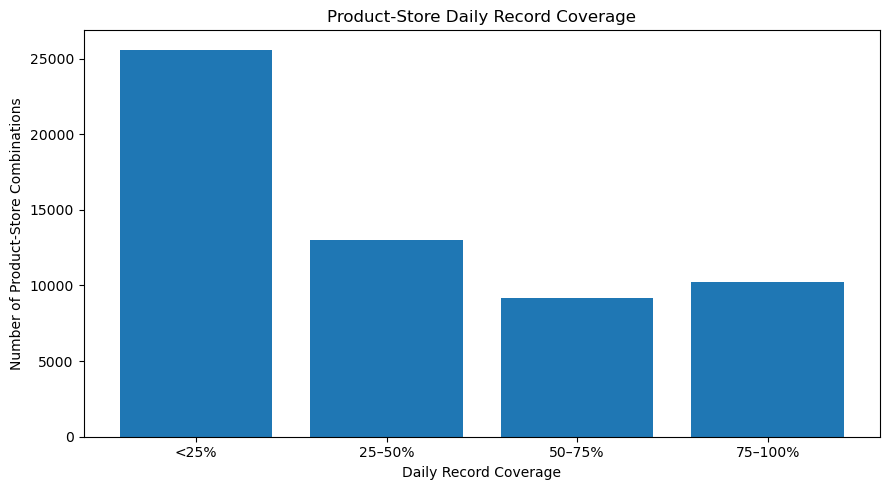

In [90]:
# Plot coverage distribution
plt.figure(figsize=(9, 5))

plt.bar(
    coverage_distribution["coverage_range"],
    coverage_distribution["combinations"]
)

plt.xlabel("Daily Record Coverage")
plt.ylabel("Number of Product-Store Combinations")
plt.title("Product-Store Daily Record Coverage")

plt.tight_layout()
plt.show()

In [91]:
# Identify highly sparse combinations
sparse_combinations = item_store_activity[
    item_store_activity["coverage_pct"] < 25
]

print(
    "Combinations with <25% coverage:",
    len(sparse_combinations)
)

print(
    "Percentage:",
    round(
        len(sparse_combinations)
        / len(item_store_activity) * 100,
        2
    ),
    "%"
)

Combinations with <25% coverage: 25410
Percentage: 43.79 %


In [93]:
# Check demand zeros
# This is separate from missing calendar days.

zero_demand = sales["quantity"].eq(0).sum()

print("Zero-quantity records:", zero_demand)
print(
    "Percentage of observed records:",
    round(zero_demand / len(sales) * 100, 4),
    "%"
)

Zero-quantity records: 2438
Percentage of observed records: 0.0328 %


# <span style="color:red"> EDA Stage 16 — Category / Product-Type Demand Analysis</span>

In [95]:
# Item type demand summary
item_type_summary = (
    sales.groupby("item_type")["quantity"]
    .agg(
        records="count",
        total_demand="sum",
        average_demand="mean",
        median_demand="median"
    )
    .sort_values("total_demand", ascending=False)
    .reset_index()
)

item_type_summary.head(15)

,item_type,records,total_demand,average_demand,median_demand
0,Unknown,691136,5563487.72,8.05,2.00
1,Упаковочный Материал,5201,2067886.00,397.59,31.00
2,Белый,60888,1553861.14,25.52,9.00
3,Пироги,41220,1137936.51,27.61,18.00
4,Пицца,47072,967282.00,20.55,10.00
5,Паучи,110436,953178.00,8.63,5.00
6,Светлое,196785,867974.00,4.41,3.00
7,Пастеризованное,50999,759520.00,14.89,7.00
8,Сдоба,33562,687335.28,20.48,13.00
9,Негазированная,39857,590612.00,14.82,6.00


In [96]:
# Check missing item types
print(
    "Missing item_type records:",
    sales["item_type"].isna().sum()
)

print(
    "Percentage:",
    round(
        sales["item_type"].isna().mean() * 100,
        2
    ),
    "%"
)

Missing item_type records: 0
Percentage: 0.0 %


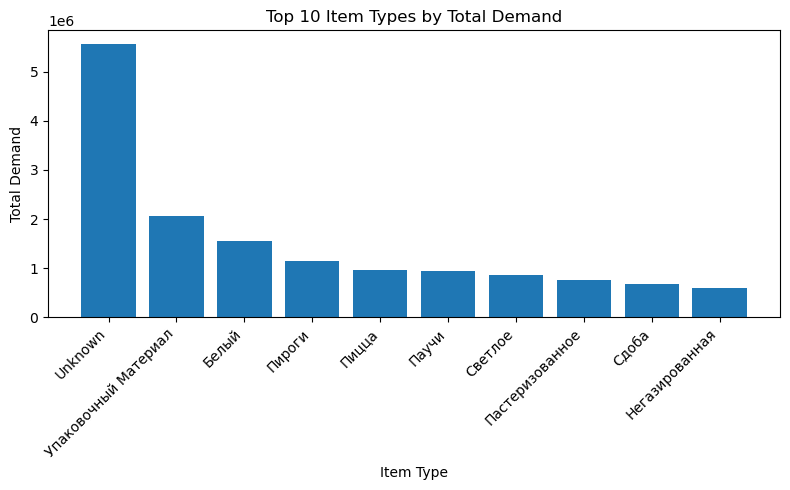

In [100]:
# Top 10 item types by total demand
top_item_types = item_type_summary.head(10)

plt.figure(figsize=(8, 5))

plt.bar(
    top_item_types["item_type"].astype(str),
    top_item_types["total_demand"]
)

plt.xlabel("Item Type")
plt.ylabel("Total Demand")
plt.title("Top 10 Item Types by Total Demand")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [98]:
# Average demand by item type
top_avg_item_types = (
    item_type_summary
    .sort_values("average_demand", ascending=False)
    .head(10)
)

top_avg_item_types

,item_type,records,total_demand,average_demand,median_demand
1,Упаковочный Материал,5201,2067886.00,397.59,31.00
25,Бананы,4203,359271.74,85.48,34.41
43,"Арбузы, Дыни",4484,227137.86,50.66,11.97
21,Картофель,8744,391857.53,44.81,7.00
190,Инжир,634,24731.44,39.01,18.00
3,Пироги,41220,1137936.51,27.61,18.00
100,Нектарины,2894,76603.53,26.47,7.50
19,Куриное,15161,394398.00,26.01,9.00
2,Белый,60888,1553861.14,25.52,9.00
38,Огурцы,11653,280595.29,24.08,6.07


# <span style="color:red">EDA Stage 17 — Numerical Feature Relationships</span>

In [101]:
# Numerical correlation matrix
numerical_cols = [
    "quantity",
    "price_base",
    "weight_volume",
    "weight_netto",
    "fatness",
    "area"
]

correlation_matrix = sales[numerical_cols].corr()
correlation_matrix

,quantity,price_base,weight_volume,weight_netto,fatness,area
quantity,1.00,-0.04,-0.02,0.03,0.02,0.03
price_base,-0.04,1.00,-0.01,0.05,0.48,0.08
weight_volume,-0.02,-0.01,1.00,0.00,-0.11,0.02
weight_netto,0.03,0.05,0.00,1.00,-0.16,-0.00
fatness,0.02,0.48,-0.11,-0.16,1.00,0.00
area,0.03,0.08,0.02,-0.00,0.00,1.00


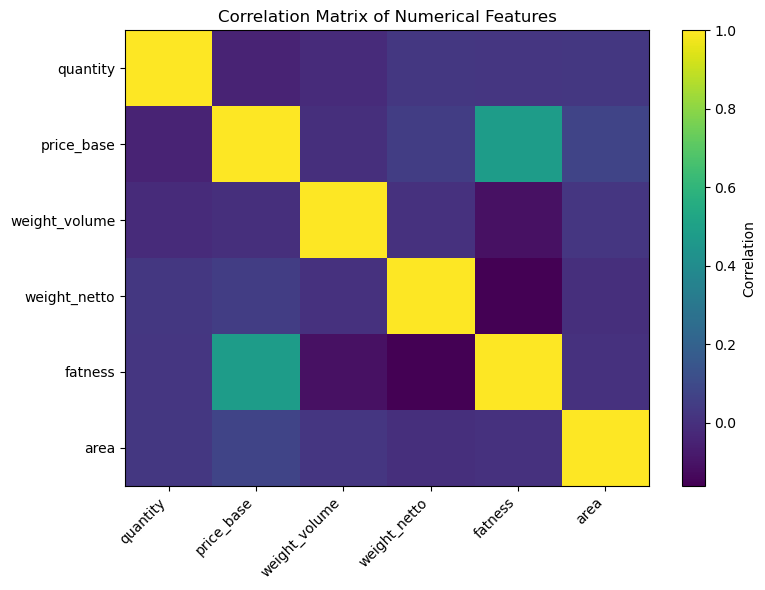

In [103]:
# Visualize correlations
plt.figure(figsize=(8, 6))

plt.imshow(
    correlation_matrix,
    aspect="auto"
)

plt.xticks(
    range(len(numerical_cols)),
    numerical_cols,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(numerical_cols)),
    numerical_cols
)

plt.colorbar(label="Correlation")

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

In [104]:
# Correlation with target

target_correlations = (
    correlation_matrix["quantity"]
    .drop("quantity")
    .sort_values(
        key=lambda x: x.abs(),
        ascending=False
    )
)

target_correlations

price_base      -0.04
weight_netto     0.03
area             0.03
fatness          0.02
weight_volume   -0.02
Name: quantity, dtype: float64

## <span style="color:purple">Verify EDA dataset</span>

In [105]:
print("Final EDA dataset shape:", sales.shape)
print("Date range:", sales["date"].min().date(), "to", sales["date"].max().date())
print("Unique products:", sales["item_id"].nunique())
print("Unique stores:", sales["store_id"].nunique())
print("Duplicate Date + item_id + store_id:",
      sales.duplicated(["date", "item_id", "store_id"]).sum())

Final EDA dataset shape: (7431525, 35)
Date range: 2022-08-28 to 2024-09-26
Unique products: 28182
Unique stores: 4
Duplicate Date + item_id + store_id: 0
